# 1. Upload and Extract Dataset Zip File

In [1]:
from google.colab import files
import zipfile
import os
import shutil

# Prompt user to upload zip file
uploaded = files.upload()

for file_name in uploaded.keys():
    if file_name.endswith('.zip'):
        print(f"Extracting {file_name}...")
        # Unzip files into casting_dataset
        with zipfile.ZipFile(file_name, 'r') as zip_ref:
            zip_ref.extractall('casting_dataset')
        print("Extraction complete!")

# Recalculate and verify downloaded structure
import glob
dataset_root = 'casting_dataset'
all_images = glob.glob(os.path.join(dataset_root, '**/*.jpeg'), recursive=True) + glob.glob(os.path.join(dataset_root, '**/*.jpg'), recursive=True)
print(f"\nNew total images found after zip upload: {len(all_images)}")

Saving casting_data-20261101T123545Z-1-001.zip to casting_data-20261101T123545Z-1-001.zip
Extracting casting_data-20261101T123545Z-1-001.zip...
Extraction complete!

New total images found after zip upload: 7348


## 2. Image Classification: Setup DataLoaders & Custom CNN


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import numpy as np
import glob
import os

# Inspect existing dataset path structure
dataset_root = 'casting_dataset'
all_images = glob.glob(os.path.join(dataset_root, '**/*.jpeg'), recursive=True) + \
             glob.glob(os.path.join(dataset_root, '**/*.jpg'), recursive=True) + \
             glob.glob(os.path.join(dataset_root, '**/*.png'), recursive=True)
print(f"Total images found: {len(all_images)}")

# Helper function to parse path to label and load image as array
def load_and_preprocess_image(path):
    # Read image
    img_raw = tf.io.read_file(path)
    img_tensor = tf.image.decode_jpeg(img_raw, channels=3)
    img_tensor = tf.image.resize(img_tensor, [224, 224])
    # Normalize image to match ImageNet range [0, 1] or preprocessing requirement
    img_tensor = img_tensor / 255.0

    # Determine label (binary: 1 if defective, 0 if normal)
    # Cast is case-insensitive
    path_lower = tf.strings.lower(path)
    is_def = tf.strings.regex_full_match(path_lower, '.*def.*')
    label = tf.cast(is_def, tf.int32)

    return img_tensor, label

Total images found: 7348


### 2.1. Data Splitting & DataLoader Setup


In [3]:
from sklearn.model_selection import train_test_split

# Split images: 75% training, 25% testing
train_paths, test_paths = train_test_split(all_images, test_size=0.25, random_state=42)

# Create TensorFlow Datasets
def make_dataset(paths, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(batch_size).prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds

train_loader_img = make_dataset(train_paths, batch_size=32, shuffle=True)
test_loader_img = make_dataset(test_paths, batch_size=32, shuffle=False)

print(f"Updated dataset split for {len(all_images)} images:")
print(f"Training images: {len(train_paths)} | Testing images: {len(test_paths)}")

Updated dataset split for 7348 images:
Training images: 5511 | Testing images: 1837


### 2.2. Architectures: Custom CNN & Transfer Learning
1. A custom CNN from scratch (convolution, pooling, dropout, dense layers).
2. Fine-tuned ResNet50
3. Fine-tuned MobileNetV2

In [4]:
# 1. Custom CNN scratch architecture
def get_custom_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),
        layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(2, activation='softmax')
    ])
    return model

# 2. ResNet50 fine-tuning setup
def get_resnet50_model():
    base_model = tf.keras.applications.ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base_model.trainable = False

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(2, activation='softmax')
    ])
    return model

# 3. MobileNetV2 fine-tuning setup
def get_mobilenet_v2_model():
    base_model = tf.keras.applications.MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base_model.trainable = False

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(2, activation='softmax')
    ])
    return model

### 2.3. Training Loop Helper
We build a training helper function to compile training states and fit each model.

In [5]:
def train_image_classifier(model, train_dataset, epochs=5):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    model.fit(train_dataset, epochs=epochs)
    return model

### 2.4. Executing Training
Custom CNN, ResNet50, and MobileNetV2 models.

In [6]:
print("Training Custom CNN...")
custom_cnn = train_image_classifier(get_custom_cnn(), train_loader_img, epochs=5)

print("\nFine-tuning ResNet50...")
resnet50 = train_image_classifier(get_resnet50_model(), train_loader_img, epochs=5)

print("\nFine-tuning MobileNetV2...")
mobilenet_v2 = train_image_classifier(get_mobilenet_v2_model(), train_loader_img, epochs=5)

Training Custom CNN...
Epoch 1/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 24s 80ms/step - accuracy: 0.6690 - loss: 0.5907
Epoch 2/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.8681 - loss: 0.3031
Epoch 3/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.9252 - loss: 0.1830
Epoch 4/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - accuracy: 0.9650 - loss: 0.1033
Epoch 5/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.9711 - loss: 0.0844

Fine-tuning ResNet50...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 33s 122ms/step - accuracy: 0.5743 - loss: 0.6773
Epoch 2/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 19s 103ms/step - accuracy: 0.6349 - loss: 0.6457
Epoch 3/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 19s 105ms/step - accuracy: 0.6748 - loss: 0.6242
Epoch 4/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 18s 102ms/step - accuracy: 0.6888 - loss: 0.6081
Epoch 5/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 100ms/step - accuracy: 0.7066 - loss: 0.5949

Fine-tuning MobileNetV2...
94

### 2.5. Evaluation & Comparison
We measure Accuracy, Precision, Recall, F1-Score, and construct Confusion Matrices for each candidate.

In [7]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import pandas as pd
import numpy as np

def evaluate_model(model, loader):
    y_true = []
    y_pred = []

    # Extract labels and inputs
    for inputs, labels in loader:
        preds = model.predict(inputs, verbose=0)
        pred_classes = np.argmax(preds, axis=1)

        y_true.extend(labels.numpy())
        y_pred.extend(pred_classes)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    return acc, prec, rec, f1, cm

results = {}
for name, model in [("Custom CNN", custom_cnn), ("ResNet50", resnet50), ("MobileNetV2", mobilenet_v2)]:
    acc, prec, rec, f1, cm = evaluate_model(model, test_loader_img)
    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1, "CM": cm}

# Construct comparison table
summary_data = []
for name, metrics in results.items():
    summary_data.append({
        "Model": name,
        "Accuracy": f"{metrics['Accuracy']:.4f}",
        "Precision": f"{metrics['Precision']:.4f}",
        "Recall": f"{metrics['Recall']:.4f}",
        "F1-Score": f"{metrics['F1-Score']:.4f}"
    })

display(pd.DataFrame(summary_data))

,Model,Accuracy,Precision,Recall,F1-Score
0,Custom CNN,0.9744,0.9644,0.9913,0.9777
1,ResNet50,0.5008,0.8371,0.1437,0.2453
2,MobileNetV2,0.9891,0.9971,0.9836,0.9903


/tmp/ipykernel_983/1954529978.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_names, y=counts, ax=axes[0, 0], palette='viridis')


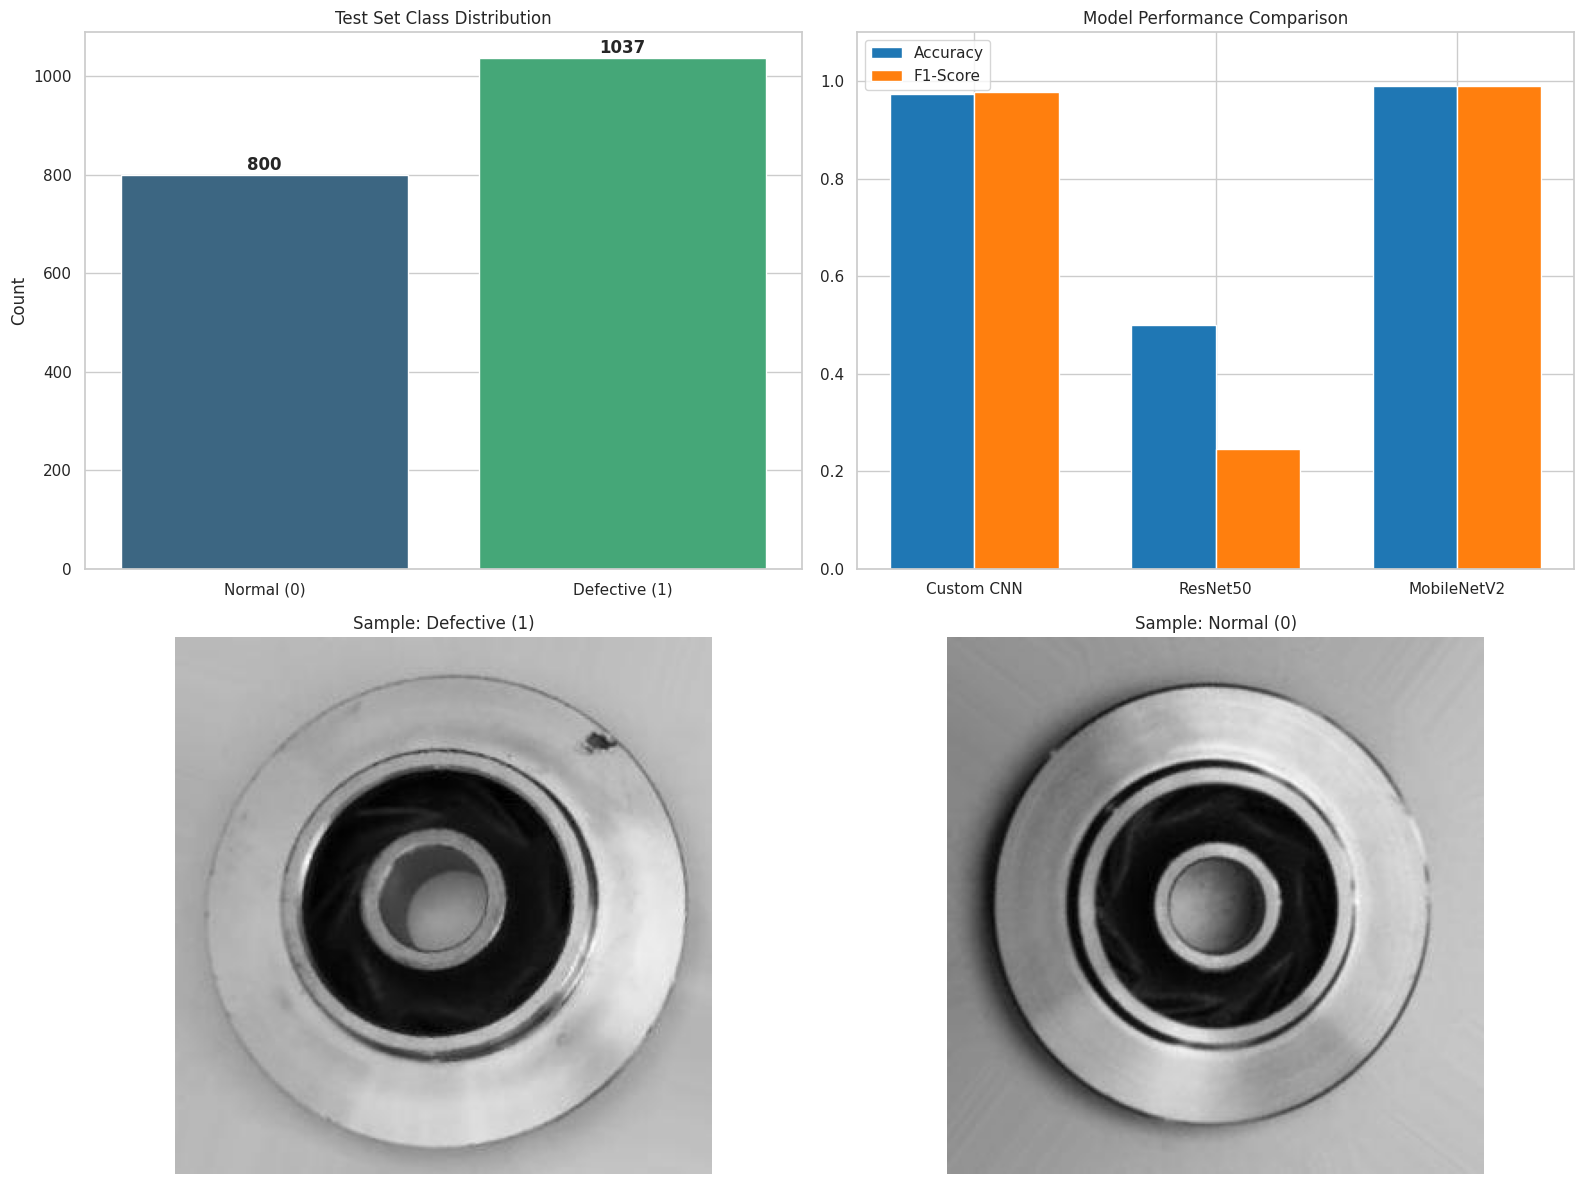

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import random

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Plot Class Distribution in Test Set
test_labels = []
for _, label in test_loader_img.unbatch():
    test_labels.append(label.numpy())

unique, counts = np.unique(test_labels, return_counts=True)
label_names = ['Normal (0)', 'Defective (1)']
sns.barplot(x=label_names, y=counts, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Test Set Class Distribution')
axes[0, 0].set_ylabel('Count')
for i, v in enumerate(counts):
    axes[0, 0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# 2. Plot Model Performance Comparison
model_names = list(results.keys())
accuracies = [results[m]['Accuracy'] for m in model_names]
f1_scores = [results[m]['F1-Score'] for m in model_names]

x = np.arange(len(model_names))
width = 0.35

axes[0, 1].bar(x - width/2, accuracies, width, label='Accuracy', color='#1f77b4')
axes[0, 1].bar(x + width/2, f1_scores, width, label='F1-Score', color='#ff7f0e')
axes[0, 1].set_title('Model Performance Comparison')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(model_names)
axes[0, 1].set_ylim(0, 1.1)
axes[0, 1].legend()

# 3. Display Sample Images (Normal and Defective)
defective_samples = [p for p in test_paths if 'def' in p.lower()][:1]
normal_samples = [p for p in test_paths if 'def' not in p.lower()][:1]

if defective_samples and normal_samples:
    img_def = cv2.imread(defective_samples[0])
    img_def = cv2.cvtColor(img_def, cv2.COLOR_BGR2RGB)
    axes[1, 0].imshow(img_def)
    axes[1, 0].set_title('Sample: Defective (1)')
    axes[1, 0].axis('off')

    img_norm = cv2.imread(normal_samples[0])
    img_norm = cv2.cvtColor(img_norm, cv2.COLOR_BGR2RGB)
    axes[1, 1].imshow(img_norm)
    axes[1, 1].set_title('Sample: Normal (0)')
    axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Save the three final models in the native Keras format
custom_cnn.save('custom_cnn.keras')
resnet50.save('resnet50.keras')
mobilenet_v2.save('mobilenet_v2.keras')

print("All three models have been saved successfully!")

All three models have been saved successfully!
